# Customer Segmentation using K-Means

## Objective
Group customers based on their annual income and spending score. This can help a business understand different types of customers.

We will use the K-Means clustering algorithm.

## 1. Import Libraries
We use Pandas to work with data, Matplotlib to make charts, and K-Means to group customers.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

## 2. Load the Dataset
Load the CSV file and display the first five rows.

In [2]:
df = pd.read_csv("../data/Mall_Customers.csv")
df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


## 3. Understand the Data
`shape` shows the number of rows and columns. `info()` shows column types and missing values. `describe()` gives basic statistics.

In [3]:
df.shape

(200, 5)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   CustomerID              200 non-null    int64
 1   Gender                  200 non-null    str  
 2   Age                     200 non-null    int64
 3   Annual Income (k$)      200 non-null    int64
 4   Spending Score (1-100)  200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 7.9 KB


In [5]:
df.describe()

,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


## 4. Select Features
For clustering, we use Annual Income and Spending Score. These two columns will help us compare customers based on income and spending behaviour.

In [6]:
X = df[["Annual Income (k$)", "Spending Score (1-100)"]]
X.head()

,Annual Income (k$),Spending Score (1-100)
0,15,39
1,15,81
2,16,6
3,16,77
4,17,40


## 5. Find the Number of Clusters (Elbow Method)
WCSS measures how close data points are to their cluster centres. We plot WCSS for different cluster counts and look for the point where the decrease starts slowing down (the elbow).

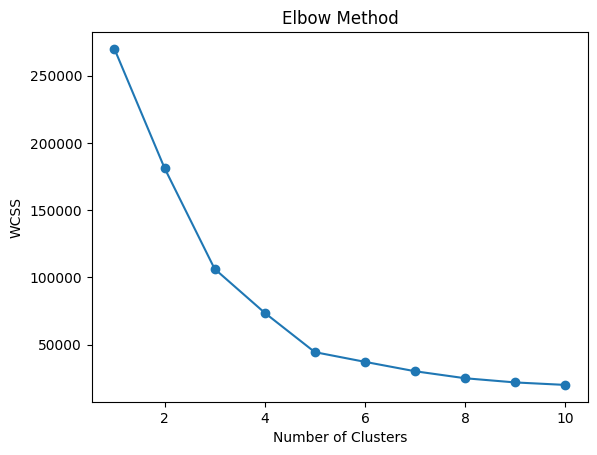

In [7]:
wcss = []

for i in range(1, 11):
    model = KMeans(n_clusters=i, random_state=42, n_init=10)
    model.fit(X)
    wcss.append(model.inertia_)

plt.plot(range(1, 11), wcss, marker="o")
plt.xlabel("Number of Clusters")
plt.ylabel("WCSS")
plt.title("Elbow Method")
plt.savefig("../charts/Elbow_Method.png")
plt.show()

## 6. Apply K-Means
Based on the elbow plot, this project uses five clusters. `fit_predict()` fits the model and assigns each customer a cluster number.

In [8]:
kmeans = KMeans(n_clusters=5, random_state=42, n_init=10)
df["Cluster"] = kmeans.fit_predict(X)

## 7. View Cluster Assignments
The new Cluster column shows which group each customer belongs to.

In [9]:
df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),Cluster
0,1,Male,19,15,39,4
1,2,Male,21,15,81,2
2,3,Female,20,16,6,4
3,4,Female,23,16,77,2
4,5,Female,31,17,40,4


## 8. Visualize the Clusters
Each point represents a customer. The colours represent the clusters and the larger points are the cluster centres (centroids).

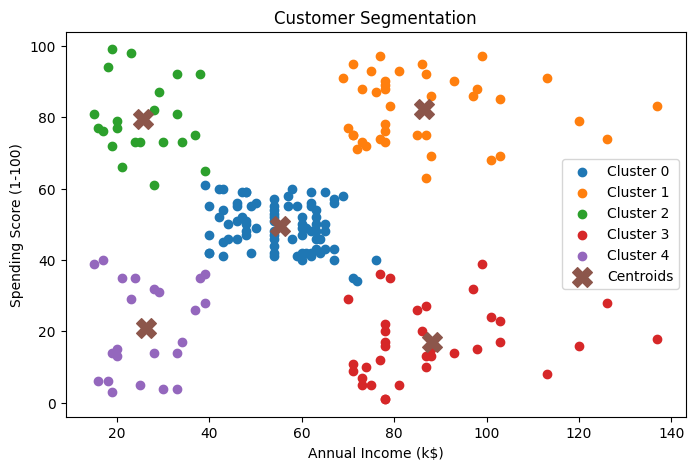

In [10]:
plt.figure(figsize=(8, 5))

for cluster in range(5):
    customers = X[df["Cluster"] == cluster]
    plt.scatter(customers["Annual Income (k$)"],
                customers["Spending Score (1-100)"],
                label=f"Cluster {cluster}")

plt.scatter(kmeans.cluster_centers_[:, 0],
            kmeans.cluster_centers_[:, 1],
            marker="X", s=200, label="Centroids")

plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.title("Customer Segmentation")
plt.legend()
plt.savefig("../charts/Customer_Segmentation.png")
plt.show()

## 9. Count Customers in Each Cluster
This tells us how many customers belong to each group.

In [11]:
df["Cluster"].value_counts().sort_index()

Cluster
0    81
1    39
2    22
3    35
4    23
Name: count, dtype: int64

## 10. Compare the Clusters
Calculate average age, income and spending score for each group. Use this table to interpret the clusters.

In [12]:
cluster_summary = df.groupby("Cluster")[
    ["Age", "Annual Income (k$)", "Spending Score (1-100)"]
].mean().round(2)

cluster_summary

,Age,Annual Income (k$),Spending Score (1-100)
Cluster,,,
0,42.72,55.30,49.52
1,32.69,86.54,82.13
2,25.27,25.73,79.36
3,41.11,88.20,17.11
4,45.22,26.30,20.91


## 11. Business Insights
Uses the cluster summary and chart to describe each group. For example, groups with higher spending scores may be good targets for promotions or loyalty campaigns. Groups with higher income but lower spending scores may respond to targeted offers. The cluster numbers themselves do not have a fixed meaning.

## 12. Save the Results
Save the dataset with its cluster assignment so it can be used later.

In [13]:
df.to_csv("../outputs/segmented_Mall_Customers.csv", index=False)
print("File saved successfully!")

File saved successfully!
